## Setup and project access

In [1]:
from pathlib import Path
import sys
import os
import json
import hashlib
import zipfile
import shutil

IN_COLAB = Path('/content').exists()
DRIVE_ROOT = Path('/content/drive/MyDrive/diplomacy_lstm')
PROJECT_NAME = 'diplomacy-deception-detection'
# Colab: optionally set a GitHub URL, otherwise upload the Phase 4 project ZIP.
GITHUB_URL = ''
PROJECT_ZIP = Path('/content/diplomacy-deception-detection-phase4.zip')
LOCAL_ROOT = Path('diplomacy-deception-detection')

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = DRIVE_ROOT / PROJECT_NAME
    DRIVE_ROOT.mkdir(parents=True, exist_ok=True)
    if not (ROOT / 'src' / 'diplomacy' / 'training' / 'phase4_runner.py').exists():
        if PROJECT_ZIP.exists():
            with zipfile.ZipFile(PROJECT_ZIP) as z:
                names = z.namelist()
                if any(name.startswith('/') or '..' in Path(name).parts for name in names):
                    raise ValueError('Unsafe ZIP paths')
                if not ROOT.exists():
                    z.extractall(DRIVE_ROOT)
                else:
                    # Existing Phase 3 Drive project: add only Phase 4 sources/configs/notebook/docs/tests.
                    # Preserve every existing Phase 1–3 artifact, trained checkpoint and source file.
                    keep = (
                        'src/diplomacy/data/phase4_context.py',
                        'src/diplomacy/embeddings/phase4_embeddings.py',
                        'src/diplomacy/models/neural/phase4.py',
                        'src/diplomacy/training/phase4_runner.py',
                        'tests/test_phase4_context.py',
                        'notebooks/12_phase_4_neural_models_colab.ipynb',
                        'docs/phase_4_neural_models.md',
                    )
                    for name in names:
                        if name.endswith('/') or not name.startswith(PROJECT_NAME + '/'):
                            continue
                        relative = name[len(PROJECT_NAME)+1:]
                        if relative in keep or relative.startswith('configs/experiments/neural/phase_4/'):
                            dest = ROOT / relative
                            dest.parent.mkdir(parents=True, exist_ok=True)
                            with z.open(name) as source, dest.open('wb') as target:
                                shutil.copyfileobj(source, target)
                    print('Added Phase 4 modules without replacing earlier artifacts.')
        elif GITHUB_URL and not ROOT.exists():
            import subprocess
            subprocess.run(['git', 'clone', GITHUB_URL, str(ROOT)], check=True)
        else:
            raise FileNotFoundError('Upload the Phase 4 ZIP (recommended for an existing Phase 3 Drive project), or configure a fresh GitHub clone.')
else:
    ROOT = LOCAL_ROOT if (LOCAL_ROOT / 'src').exists() else Path.cwd()
ROOT = ROOT.resolve()
print('Project:', ROOT)
assert (ROOT / 'src/diplomacy/training/phase4_runner.py').is_file()
sys.path.insert(0, str(ROOT/'src'))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project: /content/drive/MyDrive/diplomacy_lstm/diplomacy-deception-detection


## Install dependencies and check device

In [2]:
import importlib.util
import subprocess
for package in ('torch', 'numpy', 'pandas', 'sklearn', 'matplotlib'):
    if importlib.util.find_spec(package) is None:
        pip_name = 'scikit-learn' if package == 'sklearn' else package
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', pip_name])

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__, 'Device:', DEVICE)
if DEVICE.type == 'cuda': print('GPU:', torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130 Device: cuda
GPU: Tesla T4


## Dataset integrity and artifact storage

In [3]:
RAW_NAMES = ('train.jsonl', 'validation.jsonl', 'test.jsonl')
assert sorted(p.name for p in (ROOT/'data').iterdir() if p.is_file()) == sorted(RAW_NAMES)
RAW_HASHES = {name: hashlib.sha256((ROOT/'data'/name).read_bytes()).hexdigest() for name in RAW_NAMES}
for name, digest in RAW_HASHES.items():
    print(name, digest[:16])
for task in ('actual_lie','suspected_lie'):
    for split in ('train','validation','test'):
        file = ROOT/'artifacts'/'processed'/task/f'{split}.jsonl'
        assert file.is_file(), file
print('Original datasets and processed splits verified.')

train.jsonl 833d8ef26561bbd1
validation.jsonl 6b2ca19991c75966
test.jsonl 2061ee7f040d6d80
Original datasets and processed splits verified.


## Import the single source of truth

In [4]:
from diplomacy.training.phase4_runner import (
    ARCHITECTURES, TASKS, prepare, run_training, run_evaluation,
    load_trained, predict, predict_conversation,
    save_parity_reference, verify_parity_reference, compare_previous,
    read_config, model_dir
)
from diplomacy.data.phase4_context import chronological_games, concatenate_context
print('Architectures:', ARCHITECTURES)
print('Tasks:', TASKS)

Architectures: ('bilstm', 'bilstm_concat_context', 'hierarchical_lstm')
Tasks: ('actual_lie', 'suspected_lie')


## Run settings

In [25]:
# Run all three architectures for both tasks.
SELECTED_ARCHITECTURES = list(ARCHITECTURES)
SELECTED_TASKS = list(TASKS)
# ACTION = 'train'
ACTION = "evaluate"
DOWNLOAD_GLOVE = False
RESUME = True
EPOCHS_OVERRIDE = None
# RUN_FINAL_TEST = False
RUN_FINAL_TEST = True

assert ACTION in ('train', 'evaluate', 'predict', 'parity')
print('Selected experiments:', [(arch, task) for arch in SELECTED_ARCHITECTURES for task in SELECTED_TASKS])

Selected experiments: [('bilstm', 'actual_lie'), ('bilstm', 'suspected_lie'), ('bilstm_concat_context', 'actual_lie'), ('bilstm_concat_context', 'suspected_lie'), ('hierarchical_lstm', 'actual_lie'), ('hierarchical_lstm', 'suspected_lie')]


## Inspect experiment configurations

In [6]:
for arch in SELECTED_ARCHITECTURES:
    for task in SELECTED_TASKS:
        cfg = read_config(ROOT, arch, task)
        print(arch, task, 'model:', cfg['model'], 'context:', cfg['context'])

bilstm actual_lie model: {'embedding_dim': 200, 'hidden_size': 100, 'bidirectional': True, 'num_layers': 1, 'dropout': 0.5, 'freeze_embeddings': True} context: {'before': 3, 'after': 0, 'separator': ' <CTX> ', 'include_target': True, 'max_messages': 16}
bilstm suspected_lie model: {'embedding_dim': 200, 'hidden_size': 100, 'bidirectional': True, 'num_layers': 1, 'dropout': 0.5, 'freeze_embeddings': True} context: {'before': 3, 'after': 0, 'separator': ' <CTX> ', 'include_target': True, 'max_messages': 16}
bilstm_concat_context actual_lie model: {'embedding_dim': 200, 'hidden_size': 100, 'bidirectional': True, 'num_layers': 1, 'dropout': 0.5, 'freeze_embeddings': True} context: {'before': 3, 'after': 0, 'separator': ' <CTX> ', 'include_target': True, 'max_messages': 16}
bilstm_concat_context suspected_lie model: {'embedding_dim': 200, 'hidden_size': 100, 'bidirectional': True, 'num_layers': 1, 'dropout': 0.5, 'freeze_embeddings': True} context: {'before': 3, 'after': 0, 'separator': ' <

## Embedding availability

In [7]:
from zipfile import is_zipfile
archive = ROOT/'artifacts/embeddings/glove/glove.twitter.27B.zip'
print('GloVe path:', archive)
print('Found:', archive.exists(), 'Valid ZIP:', is_zipfile(archive) if archive.exists() else False)
print('Default phase3_glove_reuse mode uses your saved Phase 3 pretrained embeddings without this ZIP.')
print('The original ZIP is only required if you switch mode to glove.')

GloVe path: /content/drive/MyDrive/diplomacy_lstm/diplomacy-deception-detection/artifacts/embeddings/glove/glove.twitter.27B.zip
Found: True Valid ZIP: True
Default phase3_glove_reuse mode uses your saved Phase 3 pretrained embeddings without this ZIP.
The original ZIP is only required if you switch mode to glove.


## Inspect game-safe context examples

In [8]:
train_games = chronological_games(ROOT, 'train', 'actual_lie')
first_game_id = next(iter(train_games))
messages = train_games[first_game_id]
print('Game:', first_game_id, 'messages:', len(messages))
for row in messages[:3]:
    print(row['absolute_message_index'], row['message_id'], row['message'][:100].replace('\n',' '))

Game: 1 messages: 2618
0 1:13:0 Hello there! What's your general plan for this game? My inclination when I play Austria is to piss o
1 1:1:0 Hello there! What's your general plan for this game? My inclination when I play Austria is to piss o
2 1:11:0 Hello there! What's your general plan for this game? My inclination when I play Austria is to piss o


## Inspect concatenation policy

In [9]:
cfg = read_config(ROOT,'bilstm_concat_context','actual_lie')
examples = concatenate_context({first_game_id:messages[:5]},
    before=cfg['context']['before'],after=cfg['context']['after'],
    separator=cfg['context']['separator'],max_tokens=cfg['data']['max_tokens'])
for row in examples[:2]:
    print('Target:', row['message_id'], 'Source IDs:', row['context_ids'])
    print('Text:', row['message'][:180])

Target: 1:13:0 Source IDs: ['1:13:0']
Text: Hello there! What's your general plan for this game? My inclination when I play Austria is to piss off as few people as possible, so I don't plan on making any overtly aggressive m
Target: 1:1:0 Source IDs: ['1:13:0', '1:1:0']
Text: Hello there! What's your general plan for this game? My inclination when I play Austria is to piss off as few people as possible, so I don't plan on making any overtly aggressive m


## BiLSTM — individual message classification

In [10]:
print('BiLSTM reuses Phase 3 word-level BiLSTM architecture with an independent Phase 4 experiment identity.')
print('No context messages are supplied to this model.')

BiLSTM reuses Phase 3 word-level BiLSTM architecture with an independent Phase 4 experiment identity.
No context messages are supplied to this model.


## BiLSTM with concatenated context

In [11]:
print('Concatenation uses preceding messages plus the target, with an explicit separator.')
print('No messages from other games are included.')

Concatenation uses preceding messages plus the target, with an explicit separator.
No messages from other games are included.


## Hierarchical Context LSTM

In [12]:
print('The hierarchical model encodes each message, then uses a FORWARD context LSTM.')
print('Long games are split into configured max_messages chunks; context resets at chunk boundaries.')

The hierarchical model encodes each message, then uses a FORWARD context LSTM.
Long games are split into configured max_messages chunks; context resets at chunk boundaries.


## Prepare one selected experiment and inspect tensor shapes

In [13]:
# Preparation reads the shared configuration and builds the training vocabulary.
# GloVe loading may take time; this cell is opt-in to keep quick notebook inspection lightweight.
INSPECT_TENSORS = False
prepared_sample = None
if INSPECT_TENSORS:
    arch, task = SELECTED_ARCHITECTURES[0], SELECTED_TASKS[0]
    prepared_sample = prepare(ROOT, arch, task, device=DEVICE, download_glove=DOWNLOAD_GLOVE)
    batch = next(iter(prepared_sample['loaders']['train']))
    print('Input IDs:', tuple(batch['input_ids'].shape))
    if arch == 'hierarchical_lstm':
        print('Message mask:', tuple(batch['message_mask'].shape))
    print('Targets:', tuple(batch['targets'].shape))

## Execute selected training experiments

In [14]:
training_results = {}
if ACTION == 'train':
    for arch in SELECTED_ARCHITECTURES:
        for task in SELECTED_TASKS:
            print('Training:', arch, task)
            summary = run_training(ROOT, arch, task, resume=RESUME,
                epochs_override=EPOCHS_OVERRIDE, download_glove=DOWNLOAD_GLOVE,
                device=DEVICE)
            training_results[(arch,task)] = summary
            if DEVICE.type == 'cuda':
                torch.cuda.empty_cache()
print('Training runs completed in this session:', len(training_results))

Training: bilstm actual_lie
bilstm/actual_lie: vocab=7902, train_samples=13132, device=cuda
Training: bilstm suspected_lie
bilstm/suspected_lie: vocab=7654, train_samples=12025, device=cuda
bilstm/suspected_lie epoch 1: validation_macro_f1=0.3971
bilstm/suspected_lie epoch 2: validation_macro_f1=0.4373
bilstm/suspected_lie epoch 3: validation_macro_f1=0.3342
bilstm/suspected_lie epoch 4: validation_macro_f1=0.5044
bilstm/suspected_lie epoch 5: validation_macro_f1=0.5490
bilstm/suspected_lie epoch 6: validation_macro_f1=0.5223
bilstm/suspected_lie epoch 7: validation_macro_f1=0.5179
bilstm/suspected_lie epoch 8: validation_macro_f1=0.5173
bilstm/suspected_lie epoch 9: validation_macro_f1=0.5245
bilstm/suspected_lie epoch 10: validation_macro_f1=0.5276
Training: bilstm_concat_context actual_lie
bilstm_concat_context/actual_lie: vocab=7900, train_samples=13132, device=cuda
bilstm_concat_context/actual_lie epoch 1: validation_macro_f1=0.5076
bilstm_concat_context/actual_lie epoch 2: valida

## Evaluate checkpoints on validation

In [26]:
validation_results = {}
if ACTION in ('train','evaluate'):
    for arch in SELECTED_ARCHITECTURES:
        for task in SELECTED_TASKS:
            if (model_dir(ROOT,arch,task)/'best_model.pt').exists():
                result, _ = run_evaluation(ROOT,arch,task,split='validation',device=DEVICE)
                validation_results[(arch,task)] = result
                print(arch,task,'macro_f1',round(result['macro_f1'],4),'lie_f1',round(result['lie_f1'],4))

bilstm actual_lie macro_f1 0.5144 lie_f1 0.0899
bilstm suspected_lie macro_f1 0.549 lie_f1 0.1304
bilstm_concat_context actual_lie macro_f1 0.5471 lie_f1 0.125
bilstm_concat_context suspected_lie macro_f1 0.5666 lie_f1 0.1724
hierarchical_lstm actual_lie macro_f1 0.5478 lie_f1 0.1374
hierarchical_lstm suspected_lie macro_f1 0.5245 lie_f1 0.0702


## Checkpoint recovery and resume

In [27]:
for arch in SELECTED_ARCHITECTURES:
    for task in SELECTED_TASKS:
        folder = model_dir(ROOT,arch,task)
        print(arch, task, 'latest:', (folder/'latest_checkpoint.pt').exists(),
              'best:', (folder/'best_model.pt').exists())
print('Set RESUME=True and rerun training to continue an incomplete run using its latest checkpoint.')

bilstm actual_lie latest: True best: True
bilstm suspected_lie latest: True best: True
bilstm_concat_context actual_lie latest: True best: True
bilstm_concat_context suspected_lie latest: True best: True
hierarchical_lstm actual_lie latest: True best: True
hierarchical_lstm suspected_lie latest: True best: True
Set RESUME=True and rerun training to continue an incomplete run using its latest checkpoint.


## Final test evaluation

In [28]:
test_results = {}
if RUN_FINAL_TEST and ACTION in ('train','evaluate'):
    for arch in SELECTED_ARCHITECTURES:
        for task in SELECTED_TASKS:
            if (model_dir(ROOT,arch,task)/'best_model.pt').exists():
                result, predictions = run_evaluation(ROOT,arch,task,split='test',device=DEVICE)
                test_results[(arch,task)] = result
                print(arch,task,'macro_f1',round(result['macro_f1'],4))
else:
    print('Final test evaluation disabled. Enable RUN_FINAL_TEST=True after validation-based selection.')

bilstm actual_lie macro_f1 0.5479
bilstm suspected_lie macro_f1 0.5177
bilstm_concat_context actual_lie macro_f1 0.5272
bilstm_concat_context suspected_lie macro_f1 0.5135
hierarchical_lstm actual_lie macro_f1 0.5332
hierarchical_lstm suspected_lie macro_f1 0.4854


## Training curves

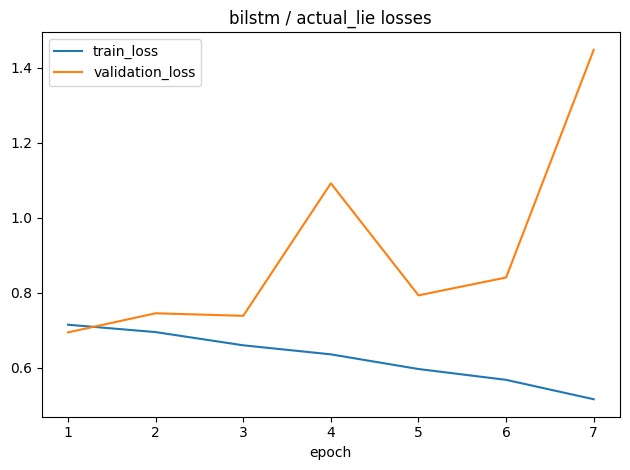

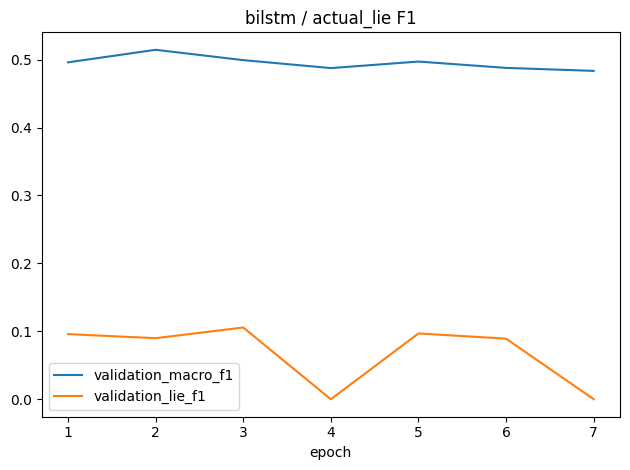

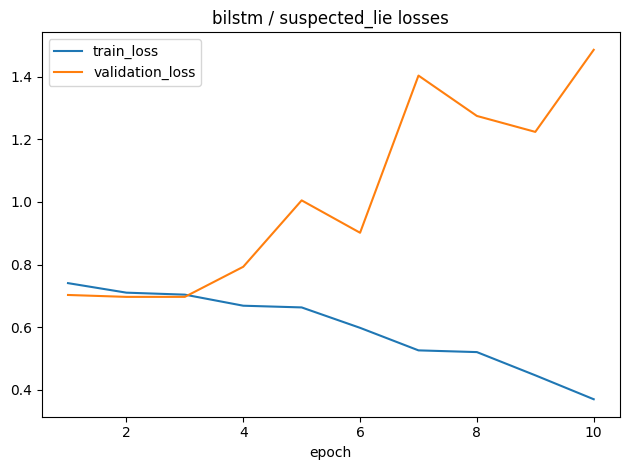

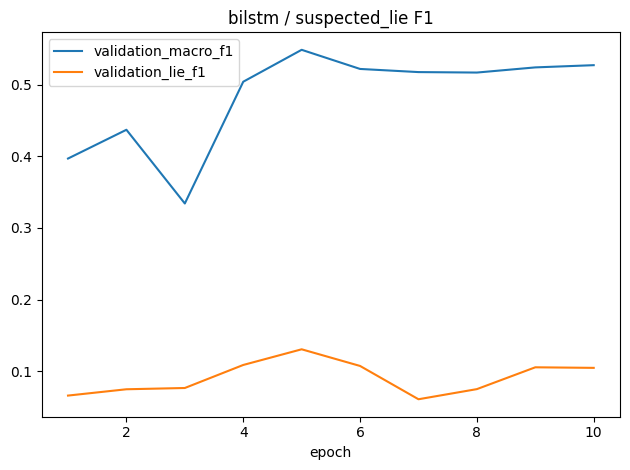

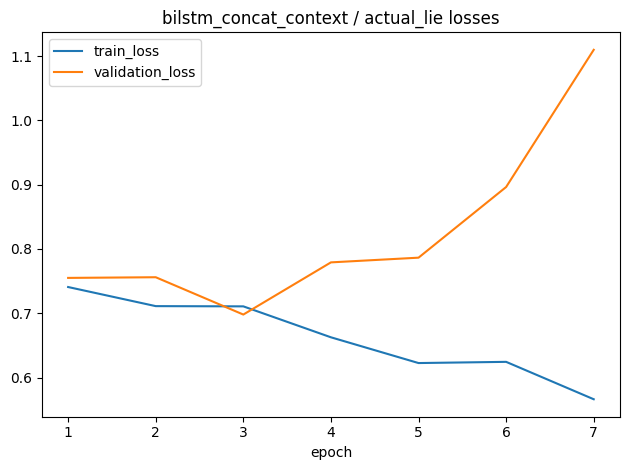

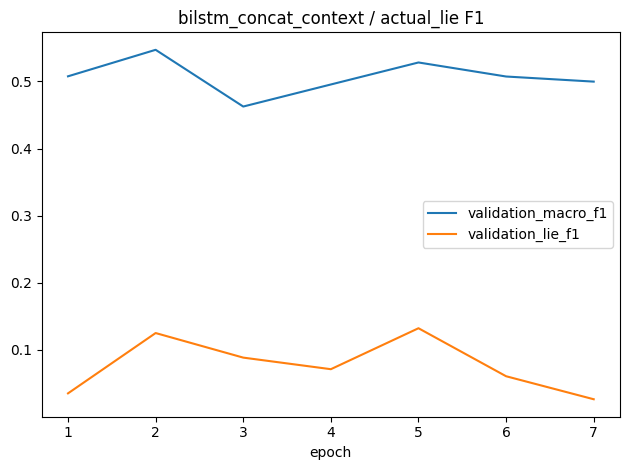

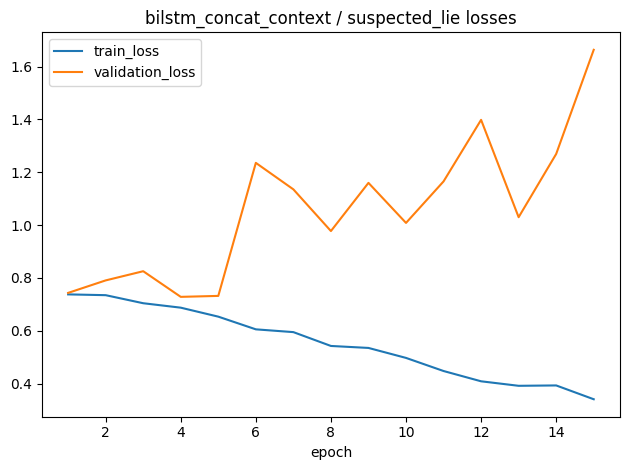

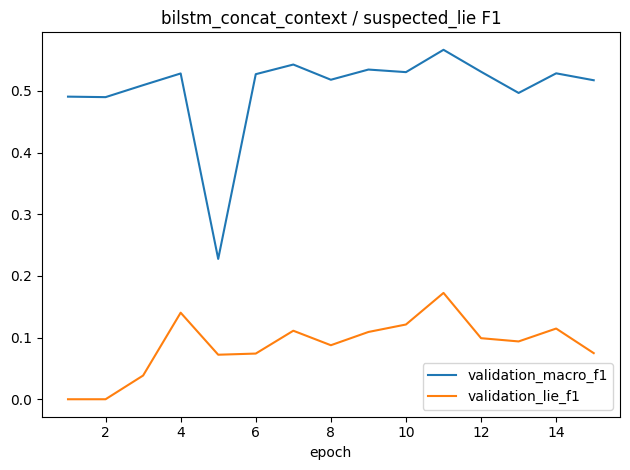

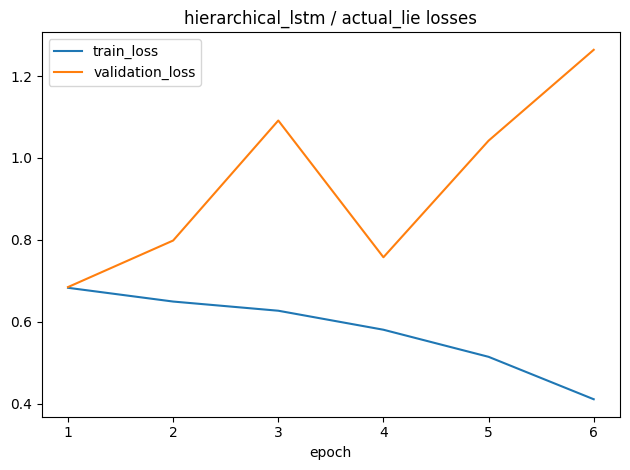

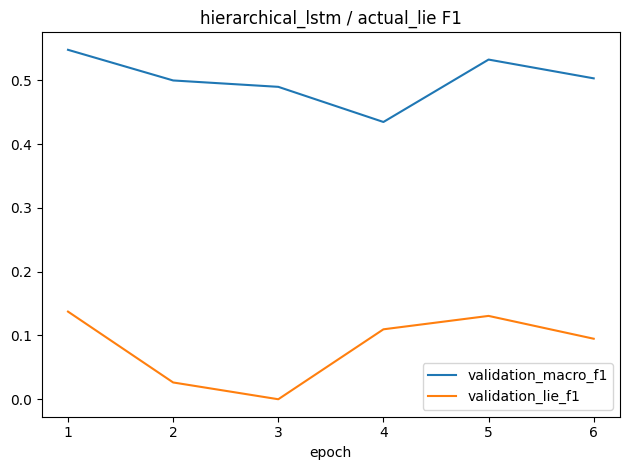

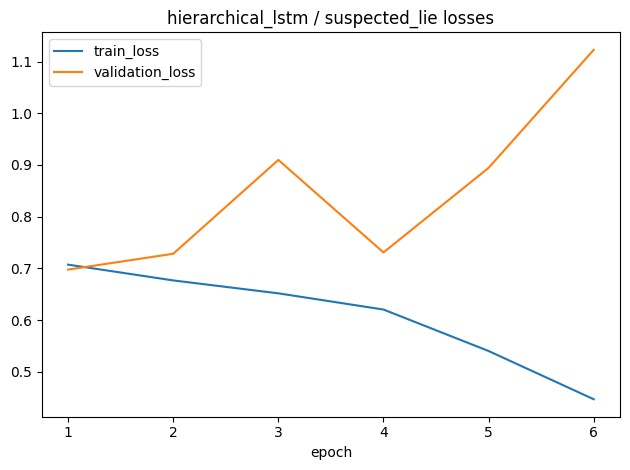

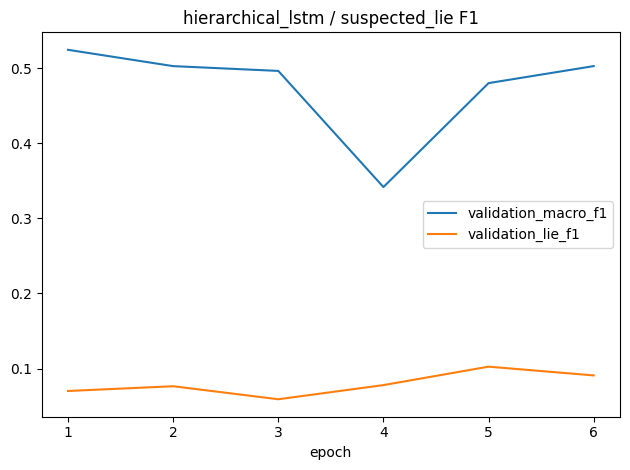

In [29]:
for arch in SELECTED_ARCHITECTURES:
    for task in SELECTED_TASKS:
        path = model_dir(ROOT,arch,task)/'history.json'
        if path.exists():
            history = pd.DataFrame(json.loads(path.read_text()))
            if not history.empty:
                history.plot(x='epoch',y=['train_loss','validation_loss'],title=f'{arch} / {task} losses')
                plt.tight_layout();plt.show()
                history.plot(x='epoch',y=['validation_macro_f1','validation_lie_f1'],title=f'{arch} / {task} F1')
                plt.tight_layout();plt.show()

## Confusion matrices

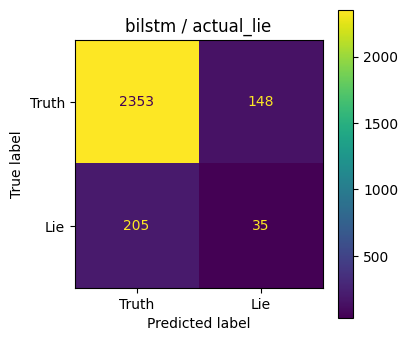

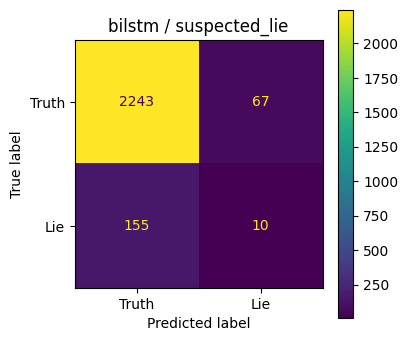

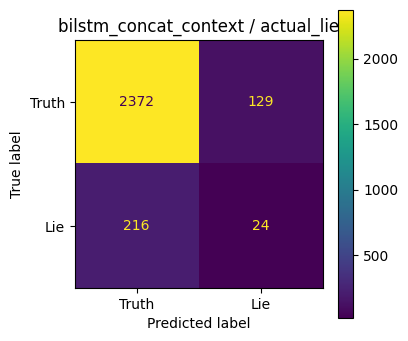

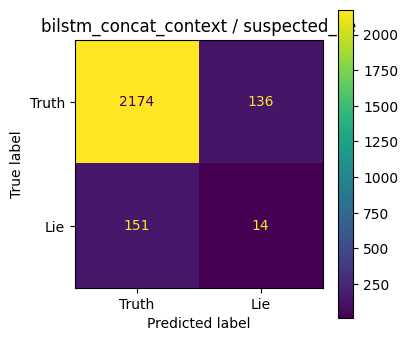

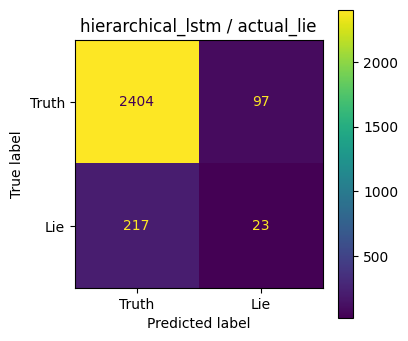

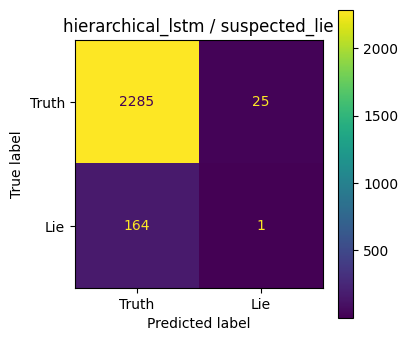

In [30]:
from sklearn.metrics import ConfusionMatrixDisplay
for (arch,task),score in test_results.items():
    fig,ax=plt.subplots(figsize=(4,4))
    ConfusionMatrixDisplay(np.array(score['confusion_matrix']),display_labels=['Truth','Lie']).plot(ax=ax,values_format='d')
    ax.set_title(f'{arch} / {task}')
    dest=ROOT/'artifacts'/'figures'/'phase_4';dest.mkdir(parents=True,exist_ok=True)
    fig.savefig(dest/f'{arch}_{task}_confusion.png',bbox_inches='tight')
    plt.show()

## Error analysis

In [31]:
for arch in SELECTED_ARCHITECTURES:
    for task in SELECTED_TASKS:
        pred_path=ROOT/'artifacts'/'predictions'/'phase_4'/arch/task/'test_predictions.csv'
        if pred_path.exists():
            frame=pd.read_csv(pred_path)
            errors=frame[frame['target']!=frame['prediction']]
            print(arch,task,'errors:',len(errors))
            output=ROOT/'artifacts'/'reports'/'phase_4';output.mkdir(parents=True,exist_ok=True)
            errors.head(50).to_csv(output/f'{arch}_{task}_test_errors.csv',index=False)

bilstm actual_lie errors: 353
bilstm suspected_lie errors: 222
bilstm_concat_context actual_lie errors: 345
bilstm_concat_context suspected_lie errors: 287
hierarchical_lstm actual_lie errors: 314
hierarchical_lstm suspected_lie errors: 189


## Local inference

In [32]:
for arch in SELECTED_ARCHITECTURES:
    for task in SELECTED_TASKS:
        if (model_dir(ROOT,arch,task)/'best_model.pt').exists():
            if arch=='hierarchical_lstm':
                answer=predict_conversation(ROOT,task,['We should cooperate.','I will support you.'],device='cpu')
            else:
                answer=predict(ROOT,arch,task,'I will support you.',context=['We should cooperate.'],device='cpu')
            print(arch,task,answer)

bilstm actual_lie {'prediction': 1, 'prob_lie': 0.5477375984191895, 'prob_truth': 0.45226240158081055}
bilstm suspected_lie {'prediction': 0, 'prob_lie': 0.4724019467830658, 'prob_truth': 0.5275980532169342}
bilstm_concat_context actual_lie {'prediction': 0, 'prob_lie': 0.4350789487361908, 'prob_truth': 0.5649210512638092}
bilstm_concat_context suspected_lie {'prediction': 0, 'prob_lie': 0.3201577961444855, 'prob_truth': 0.6798422038555145}
hierarchical_lstm actual_lie [{'message_position': 0, 'prediction': 0, 'prob_lie': 0.3886018693447113, 'prob_truth': 0.6113981306552887}, {'message_position': 1, 'prediction': 0, 'prob_lie': 0.47750383615493774, 'prob_truth': 0.5224961638450623}]
hierarchical_lstm suspected_lie [{'message_position': 0, 'prediction': 0, 'prob_lie': 0.43361803889274597, 'prob_truth': 0.566381961107254}, {'message_position': 1, 'prediction': 0, 'prob_lie': 0.4550142288208008, 'prob_truth': 0.5449857711791992}]


## Save Colab-to-local prediction parity references

In [33]:
for arch in SELECTED_ARCHITECTURES:
    for task in SELECTED_TASKS:
        if (model_dir(ROOT,arch,task)/'best_model.pt').exists():
            path=save_parity_reference(ROOT,arch,task)
            print('Saved:',path)
            print(verify_parity_reference(ROOT,arch,task))

Saved: /content/drive/MyDrive/diplomacy_lstm/diplomacy-deception-detection/artifacts/models/neural/phase_4/bilstm/actual_lie/parity_reference.json
{'architecture': 'bilstm', 'task': 'actual_lie', 'checked': 3, 'passed': True}
Saved: /content/drive/MyDrive/diplomacy_lstm/diplomacy-deception-detection/artifacts/models/neural/phase_4/bilstm/suspected_lie/parity_reference.json
{'architecture': 'bilstm', 'task': 'suspected_lie', 'checked': 3, 'passed': True}
Saved: /content/drive/MyDrive/diplomacy_lstm/diplomacy-deception-detection/artifacts/models/neural/phase_4/bilstm_concat_context/actual_lie/parity_reference.json
{'architecture': 'bilstm_concat_context', 'task': 'actual_lie', 'checked': 3, 'passed': True}
Saved: /content/drive/MyDrive/diplomacy_lstm/diplomacy-deception-detection/artifacts/models/neural/phase_4/bilstm_concat_context/suspected_lie/parity_reference.json
{'architecture': 'bilstm_concat_context', 'task': 'suspected_lie', 'checked': 3, 'passed': True}
Saved: /content/drive/My

## Compare Phases 2, 3 and 4

In [34]:
for task in TASKS:
    table=compare_previous(ROOT,task)
    print('Task:', task)
    if not table.empty:
        display(table[['phase','model','accuracy','macro_f1','lie_f1']])

Task: actual_lie


,phase,model,accuracy,macro_f1,lie_f1
0,2,01_random,0.880336,0.496792,0.057471
1,2,02_majority,0.912441,0.477108,0.000000
2,2,03_harbingers,0.912441,0.477108,0.000000
3,2,04_logistic_regression,0.669829,0.504905,0.219154
4,2,05_harbingers_lr,0.912441,0.477108,0.000000
5,2,06_harbingers_power,0.912441,0.477108,0.000000
6,2,07_harbingers_lr_power,0.912441,0.477108,0.000000
7,2,08_bow_lr,0.908063,0.509158,0.066667
8,2,09_bow_power,0.771251,0.547246,0.228782
9,2,10_bow_lr_power,0.771251,0.547246,0.228782


Task: suspected_lie


,phase,model,accuracy,macro_f1,lie_f1
0,2,01_random,0.896970,0.495246,0.044944
1,2,02_majority,0.933333,0.482759,0.000000
2,2,03_harbingers,0.933333,0.482759,0.000000
3,2,04_logistic_regression,0.933333,0.482759,0.000000
4,2,05_harbingers_lr,0.933333,0.482759,0.000000
5,2,06_harbingers_power,0.933333,0.482759,0.000000
6,2,07_harbingers_lr_power,0.933333,0.482759,0.000000
7,2,08_bow_lr,0.911111,0.506590,0.059829
8,2,09_bow_power,0.912323,0.511333,0.068670
9,2,10_bow_lr_power,0.912323,0.511333,0.068670


## Verify original files were not modified

In [35]:
for name in RAW_NAMES:
    current=hashlib.sha256((ROOT/'data'/name).read_bytes()).hexdigest()
    assert RAW_HASHES[name]==current, f'Original data changed: {name}'
print('All original raw files remain unchanged.')
print('All generated results persist under:',ROOT/'artifacts')

All original raw files remain unchanged.
All generated results persist under: /content/drive/MyDrive/diplomacy_lstm/diplomacy-deception-detection/artifacts
